# 电商落地页转化率 A/B Test 分析

某电商平台 2017-01-02 至 01-24 的落地页改版实验，29.4 万条曝光记录。用 Python 完成数据审计、效果估计、推断稳健性检验、样本量能力评估和决策建议。

### 目录

| 章节 | 内容 |
|---|---|
| 1. 研究问题与实验设计 | 实验设定与分析路线 |
| 2. 数据与字段说明 | 五个字段的含义 |
| 3. 数据可信度审计 | 完整性、分流比例（SRM）、重复上报与错配记录的结构 |
| 4. 主效应估计 | 两组转化率、效果量、95% 置信区间 |
| 5. 推断稳健性 | 六类方法对照、A/A 校准 |
| 6. 最小可检测效应（MDE） | 功效曲线、达到目标效应所需样本量 |
| 7. 时间维度检查 | 日效应、新颖性效应、按天分块 |
| 8. 序贯检验与偷看风险 | 累计 p 值路径、假阳性率膨胀、mSPRT 置信序列 |
| 9. 决策层：非劣效、等效与贝叶斯 | 三种决策工具、后验期望损失、决策矩阵 |
| 10. 敏感性分析 | 八种口径的森林图 |
| 11. 结论与建议 | 决策表述、行动项、分析边界 |
| 12. Tableau 看板 | 业务方版本 |
| 附录 | 复现说明与模拟参数 |

### 结论概览

| 问题 | 结论 |
|---|---|
| 数据质量 | 23 天分流比例正常。3,893 条分组与页面不匹配的记录来自两处系统性错位，清洗后不损失任何用户 |
| 效果 | 转化率 12.0386% → 11.8808%，差 -0.1578 个百分点（相对 -1.31%），95% CI [-0.394%, +0.078%] |
| 显著性 | $p=0.1899$，六种方法结论一致；A/A 校准的假阳性率 4.92%，检验本身正常 |
| 实验能力 | 只能检出 ≥2.80% 的相对提升，1% 的提升检出概率 17%，数据不足以做出"新页面无效"的结论 |
| 决策 | 不上线。贝叶斯期望损失 0.163 pp vs 0.005 pp；非劣效检验在 0.2 pp 界值下未通过 |

## 1. 研究问题与实验设计

平台计划用新版落地页替换现有页面，想通过随机对照实验判断值不值得全量上线。

分析要回答的是：在这批数据的质量和样本量下，能对新页面下什么结论、不能下什么结论。

### 实验设计

| 项目 | 设定 |
|---|---|
| 实验单位 | 用户（每位用户只保留首次有效实验记录） |
| 对照组 | `control`，展示 `old_page` |
| 实验组 | `treatment`，展示 `new_page` |
| 主指标 | 转化率，`converted` 的均值 |
| 显著性水平 | $\alpha=0.05$，双侧 |
| 实验周期 | 2017-01-02 至 2017-01-24，覆盖 23 个自然日 |

### 分析路线

1. 数据能不能用：分流比例、实验单位、异常记录的性质
2. 效果有多大：点估计、置信区间、多种推断方法下是否一致
3. 实验有没有能力回答：MDE 与业务阈值的比较
4. 该做什么决策：看提升、看不劣、看等价，三种目标各自的结论

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
from scipy import stats
import statsmodels.api as sm
from statsmodels.stats.proportion import proportions_ztest

RNG_SEED = 20260101
rng = np.random.default_rng(RNG_SEED)

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RAW_PATH = PROJECT_ROOT / "data" / "raw" / "ab_data.csv"
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"

# ---- 图表风格：中性白底 + 细网格 + 克制的分类配色 ----
SURFACE, INK, INK2, MUTED = "#fcfcfb", "#0b0b0b", "#52514e", "#898781"
GRID, BASE = "#e1e0d9", "#c3c2b7"
C_CTRL, C_TREAT = "#2a78d6", "#eb6834"   # 分类色槽 1 / 2
CRIT, GOOD = "#d03b3b", "#0ca30c"        # 状态色：阈值线 / 通过

mpl.rcParams.update({
    "font.sans-serif": ["Microsoft YaHei", "SimHei", "DejaVu Sans"],
    "axes.unicode_minus": False,
    "figure.dpi": 130,
    "figure.facecolor": SURFACE,
    "axes.facecolor": SURFACE,
    "savefig.facecolor": SURFACE,
    "axes.edgecolor": BASE,
    "axes.linewidth": 0.8,
    "axes.grid": True,
    "grid.color": GRID,
    "grid.linewidth": 0.7,
    "grid.linestyle": "-",
    "axes.axisbelow": True,
    "axes.titlesize": 12,
    "axes.titleweight": "semibold",
    "axes.titlecolor": INK,
    "axes.labelsize": 9.5,
    "axes.labelcolor": INK2,
    "xtick.color": MUTED,
    "ytick.color": MUTED,
    "xtick.labelsize": 9,
    "ytick.labelsize": 9,
    "legend.frameon": False,
    "legend.fontsize": 9,
    "lines.linewidth": 2,
    "text.color": INK,
})


def tidy(ax, grid_axis="y", title=None, subtitle=None):
    # 去掉多余边框，保留一条细基线，网格只画一个方向
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    for side in ("left", "bottom"):
        ax.spines[side].set_color(BASE)
    ax.grid(False)
    ax.grid(axis=grid_axis, color=GRID, lw=0.7)
    ax.set_axisbelow(True)
    if title:
        ax.set_title(title, loc="left", pad=26 if subtitle else 8)
    if subtitle:
        ax.text(0.0, 1.012, subtitle, transform=ax.transAxes,
                fontsize=9, color=INK2, va="bottom")
        ax.figure.subplots_adjust(top=0.83)
    return ax


print("环境就绪 | 随机种子:", RNG_SEED)
print("项目目录:", PROJECT_ROOT.resolve())

环境就绪 | 随机种子: 20260101
项目目录: C:\Users\Administrator\Desktop\learning materials\个人项目\电商落地页转化率 A-B Test 分析


## 2. 数据与字段说明

| 字段 | 含义 |
|---|---|
| `user_id` | 用户标识 |
| `timestamp` | 用户进入实验的时间 |
| `group` | 实验分组：`control` / `treatment` |
| `landing_page` | 用户实际看到的页面：`old_page` / `new_page` |
| `converted` | 是否转化为 1，否则 0 |

In [2]:
raw = pd.read_csv(RAW_PATH)
raw["ts"] = pd.to_datetime(raw["timestamp"])

overview = pd.DataFrame({
    "值": [
        f"{len(raw):,}",
        f"{raw['user_id'].nunique():,}",
        f"{raw.isna().sum().sum():,}",
        str(sorted(raw['converted'].unique())),
        f"{raw['ts'].min():%Y-%m-%d %H:%M} ~ {raw['ts'].max():%Y-%m-%d %H:%M}",
        f"{raw['ts'].dt.date.nunique()} 天",
    ]
}, index=[
    "原始记录数", "唯一用户 ID 数", "缺失值总数",
    "converted 取值", "时间跨度", "覆盖自然日",
])
display(overview)
display(raw.head())

,值
原始记录数,"294,478"
唯一用户 ID 数,"290,584"
缺失值总数,0
converted 取值,"[np.int64(0), np.int64(1)]"
时间跨度,2017-01-02 13:42 ~ 2017-01-24 13:41
覆盖自然日,23 天


,user_id,timestamp,group,landing_page,converted,ts
0,851104,2017-01-21 22:11:48.556739,control,old_page,0,2017-01-21 22:11:48.556739
1,804228,2017-01-12 08:01:45.159739,control,old_page,0,2017-01-12 08:01:45.159739
2,661590,2017-01-11 16:55:06.154213,treatment,new_page,0,2017-01-11 16:55:06.154213
3,853541,2017-01-08 18:28:03.143765,treatment,new_page,0,2017-01-08 18:28:03.143765
4,864975,2017-01-21 01:52:26.210827,control,old_page,1,2017-01-21 01:52:26.210827


## 3. 数据可信度审计

先看数据能不能用。实际实验里，分流错误、重复曝光和埋点错位对结论的影响往往比统计方法的选择更大。

分四步：完整性、分流比例（SRM）、实验单位污染、异常记录的结构。

In [3]:
# ---- 3.1 完整性 ----
print("分组取值:", raw["group"].value_counts().to_dict())
print("页面取值:", raw["landing_page"].value_counts().to_dict())
print("converted 合法性:", raw["converted"].isin([0, 1]).all())
print("user_id 重复记录数:", raw["user_id"].duplicated().sum())

# 分组与页面的交叉表：理想情况下只有对角线有值
display(pd.crosstab(raw["group"], raw["landing_page"], margins=True, margins_name="合计"))

分组取值: {'treatment': 147276, 'control': 147202}
页面取值: {'old_page': 147239, 'new_page': 147239}
converted 合法性: True
user_id 重复记录数: 3894


landing_page,new_page,old_page,合计
group,,,
control,1928,145274,147202
treatment,145311,1965,147276
合计,147239,147239,294478


对角线之外有 3,893 条记录（`control`+`new_page` 1,928 条，`treatment`+`old_page` 1,965 条），也就是"被分到 A 组的用户看到了 B 页面"。这个数下一节还要用到，先放这里。

In [4]:
# ---- 3.2 分流比例检查（Sample Ratio Mismatch）----
# SRM 是 A/B 平台最经典的报警：观测到的分流比例与设计比例显著偏离。
n_raw_c = (raw["group"] == "control").sum()
n_raw_t = (raw["group"] == "treatment").sum()
srm_overall = stats.chisquare([n_raw_c, n_raw_t])

day_group = raw.groupby([raw["ts"].dt.date, "group"]).size().unstack()
day_group.columns.name = None
day_rows = []
for day, row in day_group.iterrows():
    n_c, n_t = row["control"], row["treatment"]
    p_srm = stats.chisquare([n_c, n_t]).pvalue
    share = n_t / (n_c + n_t)
    se_share = np.sqrt(0.25 / (n_c + n_t))
    day_rows.append({
        "日期": day, "control": n_c, "treatment": n_t, "入组合计": n_c + n_t,
        "实验组占比": share,
        "95%CI 下限": share - 1.96 * se_share,
        "95%CI 上限": share + 1.96 * se_share,
        "SRM p 值": p_srm,
    })
daily_srm = pd.DataFrame(day_rows).set_index("日期")

print(f"全期分流: control={n_raw_c:,}  treatment={n_raw_t:,}")
print(f"全期 SRM 卡方检验 p = {srm_overall.pvalue:.4f}  ->", "未发现分流失衡" if srm_overall.pvalue > 0.05 else "存在分流失衡")
print(f"按日 SRM：p<0.05 的天数 = {(daily_srm['SRM p 值'] < 0.05).sum()} / {len(daily_srm)}"
      f"；Bonferroni 阈值 {0.05/len(daily_srm):.4f} 下超标天数 = {(daily_srm['SRM p 值'] < 0.05/len(daily_srm)).sum()}")
display(daily_srm.head(5).style.format({
    "实验组占比": "{:.2%}", "95%CI 下限": "{:.2%}", "95%CI 上限": "{:.2%}", "SRM p 值": "{:.3f}",
}))

全期分流: control=147,202  treatment=147,276
全期 SRM 卡方检验 p = 0.8915  -> 未发现分流失衡
按日 SRM：p<0.05 的天数 = 0 / 23；Bonferroni 阈值 0.0022 下超标天数 = 0


,control,treatment,入组合计,实验组占比,95%CI 下限,95%CI 上限,SRM p 值
日期,,,,,,,
2017-01-02,2894,2889,5783,49.96%,48.67%,51.25%,0.948
2017-01-03,6684,6710,13394,50.10%,49.25%,50.94%,0.822
2017-01-04,6655,6629,13284,49.90%,49.05%,50.75%,0.822
2017-01-05,6538,6586,13124,50.18%,49.33%,51.04%,0.675
2017-01-06,6684,6844,13528,50.59%,49.75%,51.43%,0.169


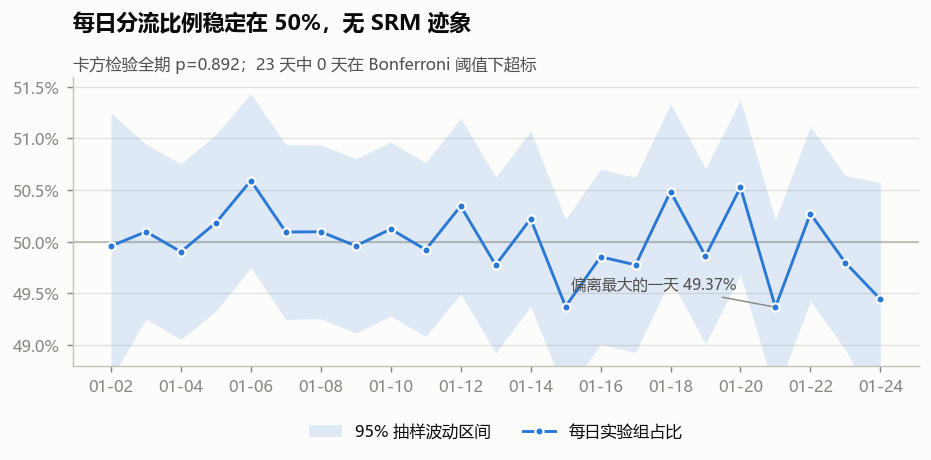

In [5]:
# 图 1：每日实验组占比是否稳定在 50%
fig, ax = plt.subplots(figsize=(8.4, 3.9))
x = np.arange(len(daily_srm))
share = daily_srm["实验组占比"].to_numpy()

ax.axhline(0.5, color=BASE, lw=1.2, zorder=1)
ax.fill_between(x, daily_srm["95%CI 下限"], daily_srm["95%CI 上限"],
                color=C_CTRL, alpha=0.14, lw=0, label="95% 抽样波动区间", zorder=2)
ax.plot(x, share, color=C_CTRL, lw=1.6, marker="o", ms=4.5,
        mec=SURFACE, mew=1.2, label="每日实验组占比", zorder=3)

worst = int(np.argmax(np.abs(share - 0.5)))
ax.annotate(f"偏离最大的一天 {share[worst]:.2%}",
            xy=(worst, share[worst]), xytext=(worst - 1.1, share[worst] + 0.0022),
            ha="right", va="center", fontsize=8.5, color=INK2,
            arrowprops=dict(arrowstyle="-", color=MUTED, lw=0.8))

ax.set_xticks(x[::2])
ax.set_xticklabels([f"{d:%m-%d}" for d in daily_srm.index][::2])
ax.set_ylim(0.488, 0.516)
ax.yaxis.set_major_formatter(PercentFormatter(1.0, decimals=1))
tidy(ax, title="每日分流比例稳定在 50%，无 SRM 迹象",
     subtitle=f"卡方检验全期 p={srm_overall.pvalue:.3f}；23 天中 0 天在 Bonferroni 阈值下超标")
ax.legend(loc="upper center", ncols=2, bbox_to_anchor=(0.5, -0.15))
ax.figure.subplots_adjust(bottom=0.26)
plt.show()

分流比例没有系统性偏差。偏离最大的一天约 0.6 个百分点（实验组占比 49.37%），仍在 95% 抽样区间内，全期卡方 $p=0.892$。

单日 SRM 检验做了 23 次，即使完全正常也会期望出现约 1 天 $p<0.05$，所以按 Bonferroni 阈值（$0.05/23$）判断，这一天也没超过。

In [6]:
# ---- 3.3 重复上报与错配记录的结构 ----
page_match = ((raw["group"] == "control") & (raw["landing_page"] == "old_page")) | (
    (raw["group"] == "treatment") & (raw["landing_page"] == "new_page")
)
raw["page_match"] = page_match

dup_ids = raw.loc[raw["user_id"].duplicated(keep=False), "user_id"].unique()
fan = (raw[raw["user_id"].isin(dup_ids)]
       .groupby("user_id")
       .agg(组数=("group", "nunique"), 页面数=("landing_page", "nunique"),
            记录数=("page_match", "size"), 错配行=("page_match", lambda s: int((~s).sum()))))

cross_group = fan[fan["组数"] == 2]                                       # 跨组重复上报
inner_leak = fan[(fan["组数"] == 1) & (fan["页面数"] == 2)]               # 组内串流
exact_dup = fan[(fan["组数"] == 1) & (fan["页面数"] == 1)]                # 完全重复

structure = pd.DataFrame({
    "用户数": [len(cross_group), len(inner_leak), len(exact_dup)],
    "记录数": [int(cross_group["记录数"].sum()), int(inner_leak["记录数"].sum()),
               int(exact_dup["记录数"].sum())],
    "错配行": [int(cross_group["错配行"].sum()), int(inner_leak["错配行"].sum()),
               int(exact_dup["错配行"].sum())],
    "结构": ["同一页面，两个分组标签", "同一分组，两个页面", "同一分组，同一页面"],
}, index=["跨组重复上报", "组内串流", "完全重复"])

display(structure.style.format({"用户数": "{:,}", "记录数": "{:,}", "错配行": "{:,}"}))
print(f"重复上报用户合计: {len(dup_ids):,} 人 / {int(fan['记录数'].sum()):,} 行")
print(f"错配行合计      : {int(fan['错配行'].sum()):,} 行  "
      f"= {int(cross_group['错配行'].sum()):,} + {int(inner_leak['错配行'].sum()):,}")

# 各类型取一位用户看明细
for name, group in [("跨组重复上报", cross_group), ("组内串流", inner_leak),
                    ("完全重复", exact_dup)]:
    uid = group.index[0]
    sample = raw[raw["user_id"] == uid].sort_values("ts")
    detail = "  +  ".join(f"{g}/{p}" for g, p in zip(sample["group"], sample["landing_page"]))
    print(f"  例｜{name}: {detail}")

,用户数,记录数,错配行,结构
跨组重复上报,"1,895","3,790","1,895",同一页面，两个分组标签
组内串流,"1,998","3,996","1,998",同一分组，两个页面
完全重复,1,2,0,同一分组，同一页面


重复上报用户合计: 3,894 人 / 7,788 行
错配行合计      : 3,893 行  = 1,895 + 1,998
  例｜跨组重复上报: control/old_page  +  treatment/old_page
  例｜组内串流: treatment/old_page  +  treatment/new_page
  例｜完全重复: treatment/new_page  +  treatment/new_page


3,894 位用户有重复记录，分两类，性质不同：

| 类型 | 用户数 | 记录结构 | 说明 |
|---|---:|---|---|
| 跨组重复上报 | 1,895 | 同一页面，两个分组标签 | `control/old_page` + `treatment/old_page`：页面没变，变的是分组标签 |
| 组内串流 | 1,998 | 同一分组，两个页面 | `control/old_page` + `control/new_page`：分组没变，页面被串 |
| 完全重复 | 1 | 同一组、同一页面 | 重复上报 |

3,893 条错配记录 = 1,895 + 1,998，正好是这两类用户各有一条与所分配版本不符的记录。

- 跨组重复上报的 1,895 人只看到过一个页面，曝光是确定的，只是分组标签写了两次，按页面归属就能定组，不用删。
- 组内串流的 1,998 人是真的曝光污染：同一分组内先后看了新旧两个页面，哪次曝光有效无法从数据判断。

清洗规则：只保留 `control→old_page`、`treatment→new_page` 的有效曝光记录，同一用户按时间取首条。跨组用户页面唯一，会自动落到与页面一致的组；串流用户保留与分组一致的那条。

清洗只删记录不删用户：294,478 行 → 290,584 行，用户数仍是 290,584。第 10 节用 as-treated 等口径检验这个处理的影响。

In [7]:
# ---- 清洗：得到主口径分析样本 ----
clean = (
    raw.loc[raw["page_match"]]
    .sort_values("ts")
    .drop_duplicates(subset="user_id", keep="first")
    .reset_index(drop=True)
)
clean = clean[["user_id", "timestamp", "ts", "group", "landing_page", "converted"]]
clean["day"] = clean["ts"].dt.date

n_c, n_t = (clean["group"] == "control").sum(), (clean["group"] == "treatment").sum()
srm_clean = stats.chisquare([n_c, n_t])

assert clean["user_id"].is_unique, "清洗后仍存在重复用户"
assert clean[["group", "landing_page"]].drop_duplicates().shape[0] == 2, "清洗后仍有错配组合"
assert len(clean) == raw["user_id"].nunique(), "清洗不应损失任何用户"

audit = pd.DataFrame({
    "检查项": ["缺失值", "converted 取值域", "记录级分流比例", "按日 SRM 超标天数",
              "跨组重复上报", "组内串流", "完全重复行", "清洗后样本", "清洗后 SRM"],
    "结果": [
        f"{raw.isna().sum().sum()} 个",
        "仅 0 / 1",
        f"p={srm_overall.pvalue:.3f}",
        f"{int((daily_srm['SRM p 值'] < 0.05 / len(daily_srm)).sum())} / {len(daily_srm)} 天",
        f"{len(cross_group):,} 人（按页面归属保留）",
        f"{len(inner_leak):,} 人（保留首次有效曝光）",
        f"{len(exact_dup):,} 行（删除）",
        f"{len(clean):,} 人 / {len(clean):,} 行（用户零损失）",
        f"p={srm_clean.pvalue:.3f}",
    ],
    "判定": ["通过", "通过", "通过", "通过", "已处理", "已处理", "已处理", "—", "通过"],
})
display(audit.style.hide(axis="index"))

# 重复上报用户的转化率是否异常（清洗后按用户的首次有效记录比较）
repeat_flag = clean["user_id"].isin(dup_ids)
print(f"重复上报用户（{repeat_flag.sum():,} 人）转化率: {clean.loc[repeat_flag, 'converted'].mean():.4%}")
print(f"其余用户（{(~repeat_flag).sum():,} 人）转化率: {clean.loc[~repeat_flag, 'converted'].mean():.4%}")

# 落盘：供 Tableau 与复现使用（保持原有字段结构）
clean_out = clean[["user_id", "timestamp", "group", "landing_page", "converted"]]
clean_out.to_csv(PROCESSED_DIR / "ab_clean.csv", index=False)
print(f"已写入 data/processed/ab_clean.csv：{len(clean_out):,} 行")

检查项,结果,判定
缺失值,0 个,通过
converted 取值域,仅 0 / 1,通过
记录级分流比例,p=0.892,通过
按日 SRM 超标天数,0 / 23 天,通过
跨组重复上报,"1,895 人（按页面归属保留）",已处理
组内串流,"1,998 人（保留首次有效曝光）",已处理
完全重复行,1 行（删除）,已处理
清洗后样本,"290,584 人 / 290,584 行（用户零损失）",—
清洗后 SRM,p=0.947,通过


重复上报用户（3,894 人）转化率: 13.0457%
其余用户（286,690 人）转化率: 11.9450%


已写入 data/processed/ab_clean.csv：290,584 行


审计小结：完整性和分流比例没问题，问题集中在两处错位，1,895 + 1,998 人，合计 3,893 条错配记录。两类错位都能在不损失任何用户的前提下修复。

另外这 3,894 位重复上报用户的转化率是 13.05%，其余用户是 11.94%（$z=2.10$，$p=0.036$）。重复上报和"高活跃、多次触达"相关，这批人不是随机子集。如果清洗规则改成"直接把这些人删掉"，会连带删掉一群高转化用户，估计值往哪边走不好判断，所以第 10 节做了口径对照。

数据可以继续用于效果估计，但清洗规则本身带判断。

## 4. 主效应估计

| 指标 | 旧页面（control） | 新页面（treatment） |
|---|---|---|
| 样本量 | $n_c$ | $n_t$ |
| 转化数 | $k_c$ | $k_t$ |
| 转化率 | $\hat p_c = k_c/n_c$ | $\hat p_t = k_t/n_t$ |

效果量报绝对差和相对提升，并给出前者的 95% 置信区间：

$$
\hat\Delta = \hat p_t - \hat p_c, \qquad
\widehat{SE}_\Delta = \sqrt{\frac{\hat p_t(1-\hat p_t)}{n_t} + \frac{\hat p_c(1-\hat p_c)}{n_c}}
$$

$$
CI_{95\%} = \hat\Delta \pm 1.96\,\widehat{SE}_\Delta
$$

In [8]:
from statsmodels.stats.proportion import proportion_confint

agg = clean.groupby("group")["converted"].agg(样本量="size", 转化数="sum", 转化率="mean")
p_c, p_t = agg.loc["control", "转化率"], agg.loc["treatment", "转化率"]
n_c, n_t = int(agg.loc["control", "样本量"]), int(agg.loc["treatment", "样本量"])
k_c, k_t = int(agg.loc["control", "转化数"]), int(agg.loc["treatment", "转化数"])

delta = p_t - p_c
se_delta = np.sqrt(p_t * (1 - p_t) / n_t + p_c * (1 - p_c) / n_c)
z_stat = delta / se_delta
p_value = 2 * stats.norm.sf(abs(z_stat))
ci_low, ci_high = delta - 1.96 * se_delta, delta + 1.96 * se_delta
rel_lift = delta / p_c

ci_c = proportion_confint(k_c, n_c, method="wilson")
ci_t = proportion_confint(k_t, n_t, method="wilson")

result = pd.DataFrame({
    "样本量": [n_c, n_t, n_c + n_t],
    "转化数": [k_c, k_t, k_c + k_t],
    "转化率": [p_c, p_t, (k_c + k_t) / (n_c + n_t)],
    "转化率 95%CI": [f"[{ci_c[0]:.4%}, {ci_c[1]:.4%}]", f"[{ci_t[0]:.4%}, {ci_t[1]:.4%}]", "—"],
}, index=["旧页面 control", "新页面 treatment", "合计"])
display(result.style.format({"样本量": "{:,}", "转化数": "{:,}", "转化率": "{:.4%}"}))

print(f"绝对变化 Δ      = {delta*100:+.4f} 个百分点   (新 - 旧)")
print(f"相对变化         = {rel_lift:+.2%}")
print(f"标准误 SE(Δ)     = {se_delta*100:.4f} 个百分点")
print(f"z 统计量         = {z_stat:.4f}")
print(f"双侧 p 值        = {p_value:.4f}")
print(f"95% 置信区间     = [{ci_low*100:+.4f}%, {ci_high*100:+.4f}%]")
print(f"区间宽度         = {(ci_high - ci_low)*100:.4f} 个百分点")

# 同步 Tableau 看板的数据源（保持原有长表结构，原看板无需改动）
tableau_summary = pd.DataFrame({
    "metric": ["旧页面转化率", "新页面转化率", "绝对变化", "p 值", "置信区间下限", "置信区间上限"],
    "value": [p_c, p_t, delta, p_value, ci_low, ci_high],
})
tableau_summary.to_csv(PROCESSED_DIR / "tableau_summary.csv", index=False)
print("\n已写入 data/processed/tableau_summary.csv（Tableau 看板数据源）")

,样本量,转化数,转化率,转化率 95%CI
旧页面 control,"145,274","17,489",12.0386%,"[11.8723%, 12.2070%]"
新页面 treatment,"145,310","17,264",11.8808%,"[11.7154%, 12.0482%]"
合计,"290,584","34,753",11.9597%,—


绝对变化 Δ      = -0.1578 个百分点   (新 - 旧)
相对变化         = -1.31%
标准误 SE(Δ)     = 0.1204 个百分点
z 统计量         = -1.3109
双侧 p 值        = 0.1899
95% 置信区间     = [-0.3938%, +0.0781%]
区间宽度         = 0.4719 个百分点

已写入 data/processed/tableau_summary.csv（Tableau 看板数据源）


新页面比旧页面低 0.1578 个百分点，相对 -1.31%。95% 区间 $[-0.394\%,\ +0.078\%]$ 跨 0：真实效果可能是一定的下降（最低约 -0.39 pp），也可能是很小的提升（最高约 +0.08 pp）。

区间并没有收窄到 0 附近，只是不够窄到能排除 0。第 6 节算一下在当前样本量下这个区间最窄能到多少。

## 5. 推断稳健性

单一方法的 $p$ 值可能受检验假设、方差估计方式影响。这里用六种方法交叉验证同一个结论，再用 A/A 校准确认这套检验在真无差异时不会误报。

In [9]:
# ---- 5.1 六类方法对照（七行，其中卡方无校正与 z 检验等价） ----
table = np.array([[k_t, n_t - k_t], [k_c, n_c - k_c]])
methods = []

z_s, p_z = proportions_ztest([k_t, k_c], [n_t, n_c])
methods.append(("两比例 z 检验（合并方差）", z_s, p_z, "主分析口径"))

chi2_ny = stats.chi2_contingency(table, correction=False)
methods.append(("卡方检验（无连续性校正）", np.sqrt(chi2_ny[0]) * np.sign(delta), chi2_ny[1], "等价于 z 检验"))

chi2_y = stats.chi2_contingency(table, correction=True)
methods.append(("卡方检验（Yates 校正）", np.nan, chi2_y[1], "小样本更保守"))

_, p_fisher = stats.fisher_exact(table)
methods.append(("Fisher 精确检验", np.nan, p_fisher, "不依赖正态近似"))

df_logit = clean[["converted"]].copy()
df_logit["treat"] = (clean["group"] == "treatment").astype(int)
logit = sm.Logit(df_logit["converted"], sm.add_constant(df_logit["treat"])).fit(
    disp=False, cov_type="HC3"
)
methods.append(("logistic 回归（HC3 稳健标准误）",
                logit.params["treat"] / logit.bse["treat"], logit.pvalues["treat"],
                f"OR={np.exp(logit.params['treat']):.4f}"))

# 置换检验：置换群组标签时，实验组转化数服从超几何分布，可直接精确抽样
K, N = k_c + k_t, n_c + n_t
draws = rng.hypergeometric(K, N - K, n_t, size=50_000)
perm_delta = draws / n_t - (K - draws) / n_c
p_perm = np.mean(np.abs(perm_delta) >= abs(delta))
methods.append(("置换检验（50,000 次）", np.nan, p_perm, "不依赖分布假设"))

# bootstrap：对 0/1 数据重抽样，转化数等价于二项抽样
bs = rng.binomial(n_t, p_t, 20_000) / n_t - rng.binomial(n_c, p_c, 20_000) / n_c
bs_low, bs_high = np.percentile(bs, [2.5, 97.5])
p_boot = 2 * min(np.mean(bs <= 0), np.mean(bs >= 0))
methods.append(("bootstrap（20,000 次）", np.nan, p_boot,
                f"95%CI=[{bs_low*100:+.3f}%, {bs_high*100:+.3f}%]"))

comparison = pd.DataFrame(methods, columns=["方法", "统计量", "p 值", "备注"]).set_index("方法")
display(comparison.style.format({"统计量": "{:.4f}", "p 值": "{:.4f}"}, na_rep="—"))

p_values = comparison["p 值"]
print(f"p 值范围: {p_values.min():.4f} ~ {p_values.max():.4f}；"
      f"全部 > 0.05: {bool((p_values > 0.05).all())}")
print(f"bootstrap 与解析区间的端点差: "
      f"下界 {abs(bs_low - ci_low)*100:.5f} pp, 上界 {abs(bs_high - ci_high)*100:.5f} pp")

,统计量,p 值,备注
方法,,,
两比例 z 检验（合并方差）,-1.3109,0.1899,主分析口径
卡方检验（无连续性校正）,-1.3109,0.1899,等价于 z 检验
卡方检验（Yates 校正）,—,0.1918,小样本更保守
Fisher 精确检验,—,0.1905,不依赖正态近似
logistic 回归（HC3 稳健标准误）,-1.3109,0.1899,OR=0.9851
"置换检验（50,000 次）",—,0.1922,不依赖分布假设
"bootstrap（20,000 次）",—,0.1825,"95%CI=[-0.392%, +0.073%]"


p 值范围: 0.1825 ~ 0.1922；全部 > 0.05: True
bootstrap 与解析区间的端点差: 下界 0.00195 pp, 上界 0.00467 pp


In [10]:
# ---- 5.2 A/A 校准：把对照组随机分成两半，看真无差异时检验的表现 ----
n_aa = n_c
k_aa = k_c
n_a = n_aa // 2
SIMS_AA = 5_000

ka = rng.hypergeometric(k_aa, n_aa - k_aa, n_a, size=SIMS_AA)   # 精确的随机二分组
kb = k_aa - ka
pa, pb = ka / n_a, kb / (n_aa - n_a)
d_aa = pb - pa
se_aa = np.sqrt(pa * (1 - pa) / n_a + pb * (1 - pb) / (n_aa - n_a))
p_aa = 2 * stats.norm.sf(np.abs(d_aa / se_aa))
covered = np.abs(d_aa) <= 1.96 * se_aa

fpr = np.mean(p_aa < 0.05)
coverage = np.mean(covered)
print(f"A/A 模拟次数        : {SIMS_AA:,}（每组 {n_a:,} 人）")
print(f"假阳性率 (α=0.05)   : {fpr:.4f}   —— 名义值 0.05")
print(f"95%CI 覆盖率        : {coverage:.4f}   —— 名义值 0.95")
print(f"二项 95% 抽样范围   : [{0.05 - 1.96*np.sqrt(0.05*0.95/SIMS_AA):.4f}, "
      f"{0.05 + 1.96*np.sqrt(0.05*0.95/SIMS_AA):.4f}]")

A/A 模拟次数        : 5,000（每组 72,637 人）
假阳性率 (α=0.05)   : 0.0492   —— 名义值 0.05
95%CI 覆盖率        : 0.9508   —— 名义值 0.95
二项 95% 抽样范围   : [0.0440, 0.0560]


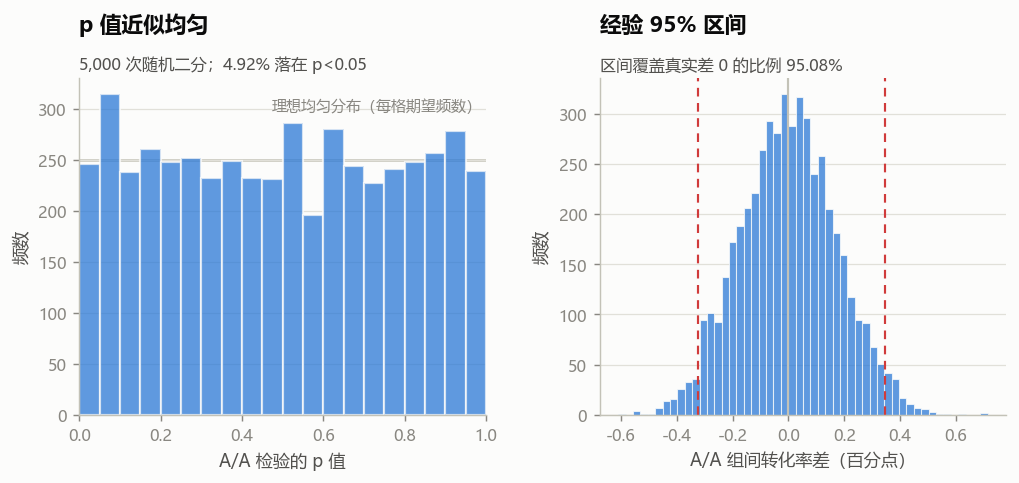

In [11]:
# 图 2：A/A 下 p 值应服从均匀分布（左）；CI 覆盖率应贴近 95%（右）
fig, axes = plt.subplots(1, 2, figsize=(9.2, 3.6), gridspec_kw={"wspace": 0.28})

ax = axes[0]
ax.hist(p_aa, bins=20, range=(0, 1), color=C_CTRL, alpha=0.75,
        edgecolor=SURFACE, linewidth=1.2)
ax.axhline(SIMS_AA / 20, color=BASE, lw=1.4, zorder=0)
ax.text(0.99, SIMS_AA / 20 * 1.18, "理想均匀分布（每格期望频数）", ha="right", va="bottom",
        fontsize=8.3, color=MUTED)
ax.set_xlabel("A/A 检验的 p 值")
ax.set_ylabel("频数")
ax.set_xlim(0, 1)
tidy(ax, title="p 值近似均匀", subtitle=f"{SIMS_AA:,} 次随机二分；{fpr:.2%} 落在 p<0.05")

ax = axes[1]
ax.hist(d_aa * 100, bins=50, color=C_CTRL, alpha=0.75, edgecolor=SURFACE, linewidth=0.6)
ax.axvline(0, color=BASE, lw=1.2)
for v in (np.percentile(d_aa, 2.5) * 100, np.percentile(d_aa, 97.5) * 100):
    ax.axvline(v, color=CRIT, lw=1.2, ls=(0, (4, 3)), zorder=1)
ax.set_xlabel("A/A 组间转化率差（百分点）")
ax.set_ylabel("频数")
tidy(ax, title="经验 95% 区间", subtitle=f"区间覆盖真实差 0 的比例 {coverage:.2%}")

plt.show()  # 两个子图共用同一套标题与留白设置

六种方法的 $p$ 值都在 0.18–0.19，没有一种接近 0.05，结论不依赖某个特定检验的假设。给出最大 $p$ 值的 Fisher 精确检验也只有 0.19，不属于擦边。

A/A 校准：把 `control` 组随机分成两半跑 5,000 次，假阳性率 4.92%（名义 5%）、区间覆盖率 95.08%（名义 95%），都落在二项抽样波动范围内。检验本身没有偏严或偏松，0.1899 是真实的"没有证据"。

A/A 的原理是两半来自同一个总体，真实差为 0；如果这时候 $p$ 值仍频繁小于 0.05，说明检验或方差估计有偏。

## 6. 最小可检测效应（MDE）

$p>0.05$ 有两种解释：新页面真的没有提升，或者实验根本没能力检出这个量级的提升。区分这两种情况看最小可检测效应（Minimum Detectable Effect, MDE）：

$$
\text{MDE} = (z_{1-\alpha/2} + z_{1-\beta}) \times \widehat{SE}_\Delta
$$

即在给定样本量和 80% 功效下，实验有 80% 概率判定为显著的最小真实效应。

In [12]:
z_alpha = stats.norm.ppf(1 - 0.025)
z_beta = stats.norm.ppf(0.80)
mde_abs = (z_alpha + z_beta) * se_delta
mde_rel = mde_abs / p_c

print(f"当前样本量        : 每臂约 {n_c:,} / {n_t:,}")
print(f"MDE（80% 功效）   : {mde_abs*100:.4f} 个百分点 = 相对 {mde_rel:.2%}")
print(f"观测到的绝对变化  : {delta*100:.4f} 个百分点 = 相对 {rel_lift:.2%}")
print(f"观测效应 / MDE    : {abs(delta)/mde_abs:.2%}")
print(f"MDE 对应的转化率  : {p_c:.2%} -> {p_c*(1+mde_rel):.2%}")

# 达到指定相对提升所需的样本量（双侧、α=0.05、80% 功效、两臂均等）
targets = pd.DataFrame({"目标相对提升": [0.005, 0.01, 0.015, 0.02, 0.03]})
targets["目标转化率"] = p_c * (1 + targets["目标相对提升"])
daily_traffic = len(clean) / clean["day"].nunique()

def required_n(p1, p2, alpha=0.05, power=0.80):
    za, zb = stats.norm.ppf(1 - alpha / 2), stats.norm.ppf(power)
    return (za + zb) ** 2 * (p1 * (1 - p1) + p2 * (1 - p2)) / (p2 - p1) ** 2

targets["每臂所需样本"] = [required_n(p_c, p, 0.05, 0.80) for p in targets["目标转化率"]]
targets["总样本量"] = targets["每臂所需样本"] * 2
targets["按当前流量需天数"] = targets["总样本量"] / daily_traffic
targets["相对当前样本"] = targets["总样本量"] / len(clean)

display(targets.style.format({
    "目标相对提升": "{:.1%}", "目标转化率": "{:.4%}",
    "每臂所需样本": "{:,.0f}", "总样本量": "{:,.0f}",
    "按当前流量需天数": "{:.0f} 天", "相对当前样本": "{:.1f}×",
}).hide(axis="index"))

当前样本量        : 每臂约 145,274 / 145,310
MDE（80% 功效）   : 0.3373 个百分点 = 相对 2.80%
观测到的绝对变化  : -0.1578 个百分点 = 相对 -1.31%
观测效应 / MDE    : 46.79%
MDE 对应的转化率  : 12.04% -> 12.38%


目标相对提升,目标转化率,每臂所需样本,总样本量,按当前流量需天数,相对当前样本
0.5%,12.0988%,"4,597,777","9,195,555",728 天,31.6×
1.0%,12.1590%,"1,151,913","2,303,827",182 天,7.9×
1.5%,12.2192%,"513,057","1,026,114",81 天,3.5×
2.0%,12.2794%,"289,210","578,420",46 天,2.0×
3.0%,12.3998%,"129,083","258,167",20 天,0.9×


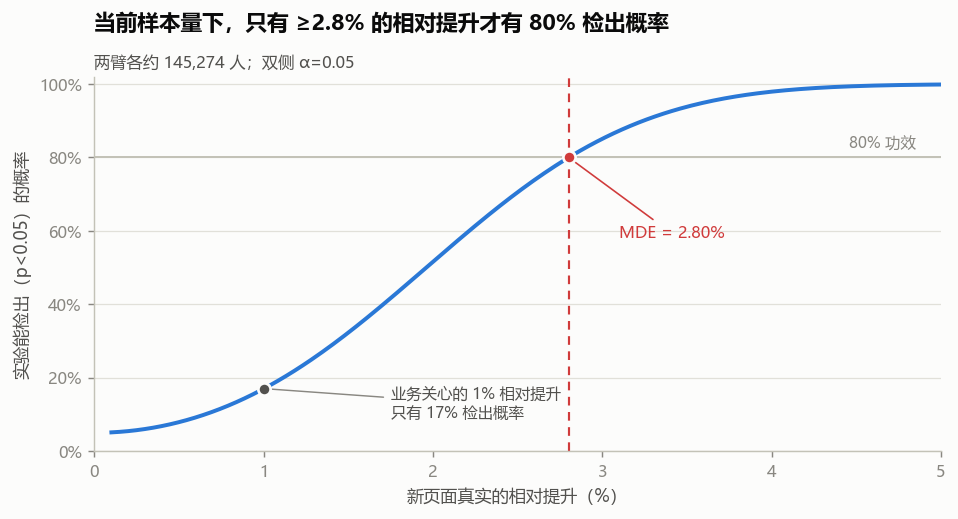

In [13]:
# 图 3：当前样本量下的功效曲线 —— 能不能检出，取决于效应有多大
rel_grid = np.linspace(0.001, 0.05, 300)
effect = rel_grid * p_c
power_curve = stats.norm.sf(z_alpha - effect / se_delta) + stats.norm.cdf(-z_alpha - effect / se_delta)

fig, ax = plt.subplots(figsize=(8.4, 4.0))
ax.plot(rel_grid * 100, power_curve, color=C_CTRL, lw=2.2)

ax.axhline(0.80, color=BASE, lw=1.1)
ax.text(4.85, 0.815, "80% 功效", fontsize=8.5, color=MUTED, ha="right", va="bottom")
ax.axvline(mde_rel * 100, color=CRIT, lw=1.2, ls=(0, (4, 3)))
ax.scatter([mde_rel * 100], [0.80], s=46, color=CRIT, zorder=4,
           edgecolor=SURFACE, linewidth=1.5)
ax.annotate(f"MDE = {mde_rel:.2%}", xy=(mde_rel * 100, 0.80),
            xytext=(mde_rel * 100 + 0.30, 0.58), fontsize=9, color=CRIT,
            arrowprops=dict(arrowstyle="-", color=CRIT, lw=0.9))

power_1pct = power_curve[np.argmin(np.abs(rel_grid - 0.01))]
ax.scatter([1.0], [power_1pct], s=46, color=INK2, zorder=4,
           edgecolor=SURFACE, linewidth=1.5)
ax.annotate(f"业务关心的 1% 相对提升\n只有 {power_1pct:.0%} 检出概率",
            xy=(1.0, power_1pct), xytext=(1.75, 0.09), fontsize=8.5, color=INK2,
            arrowprops=dict(arrowstyle="-", color=MUTED, lw=0.8))

ax.set_xlabel("新页面真实的相对提升（%）")
ax.set_ylabel("实验能检出（p<0.05）的概率")
ax.set_ylim(0, 1.02)
ax.set_xlim(0, 5)
ax.yaxis.set_major_formatter(PercentFormatter(1.0, decimals=0))
tidy(ax, title="当前样本量下，只有 ≥2.8% 的相对提升才有 80% 检出概率",
     subtitle=f"两臂各约 {n_c:,} 人；双侧 α=0.05")
plt.show()

这一节改变了结论的表述方式：

- 本轮 MDE 是 2.80% 的相对提升，而落地页改版通常只有 0.5%–1.5% 的相对变化。
- 如果业务关心的是 1% 的提升，本轮实验只有约 17% 的概率能发现它。新页面真的提升 1% 时，五次里有四次会得到同样的不显著结果。
- 要可靠检出 1%，每臂需要约 115 万人，按 12,634 人/天的进入量要跑 182 天，本轮只跑了 22 天。

所以能说出口的是：本轮实验分不清"新页面没有提升"和"新页面有小幅提升"，在现有样本量下得到不显著的结果，信息量很低。

这也是第 9 节决策建议的依据。

## 7. 时间维度检查

实验跑了 23 天。如果效果随时间漂移，全期平均就会掩盖结构性问题，也会影响以后实验该跑多久。

看两件事：

- 新颖性效应：用户对新界面短期好奇，转化率前高后低（或相反），全期平均会高估或低估长期效果。
- 日间差异能不能用来分块降方差。

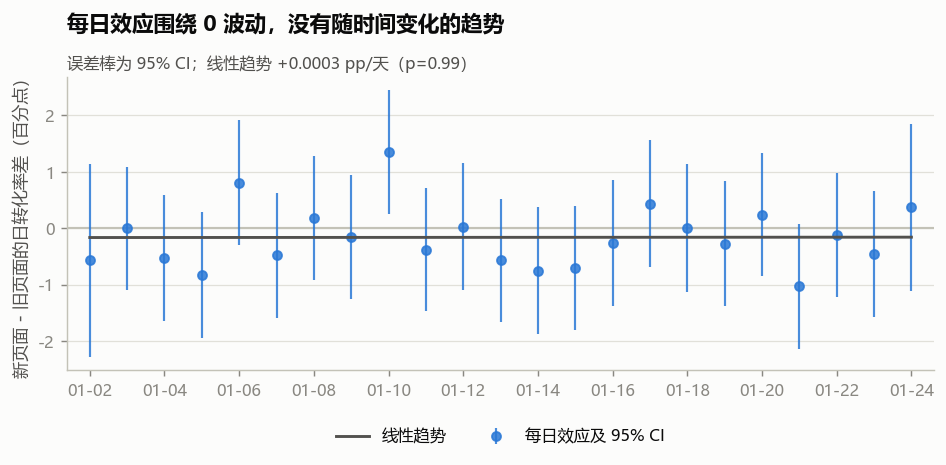

,mean_control,mean_treatment,差值_pp,效应SE_pp
day,,,,
2017-01-22,11.92%,11.80%,-0.115,0.561
2017-01-23,12.57%,12.11%,-0.461,0.569
2017-01-24,11.80%,12.17%,+0.370,0.753


In [14]:
# ---- 7.1 每日转化率与日效应 ----
daily = clean.groupby(["day", "group"])["converted"].agg(["mean", "size", "sum"]).unstack()
daily.columns = [f"{a}_{b}" for a, b in daily.columns]
daily["差值_pp"] = (daily["mean_treatment"] - daily["mean_control"]) * 100
daily["效应SE_pp"] = np.sqrt(
    daily["mean_treatment"] * (1 - daily["mean_treatment"]) / daily["size_treatment"]
    + daily["mean_control"] * (1 - daily["mean_control"]) / daily["size_control"]
) * 100

x = np.arange(len(daily))
slope_res = stats.linregress(x, daily["差值_pp"].to_numpy())

fig, ax = plt.subplots(figsize=(8.6, 4.1))
ax.axhline(0, color=BASE, lw=1.2, zorder=1)
ax.errorbar(x, daily["差值_pp"], yerr=1.96 * daily["效应SE_pp"],
            fmt="o", ms=5, color=C_CTRL, ecolor=C_CTRL, elinewidth=1.2,
            capsize=0, alpha=0.85, zorder=3, label="每日效应及 95% CI")

trend = np.polyval(np.polyfit(x, daily["差值_pp"], 1), x)
ax.plot(x, trend, color=INK2, lw=1.6, zorder=4, label="线性趋势")

ax.set_xticks(x[::2])
ax.set_xticklabels([f"{d:%m-%d}" for d in daily.index][::2])
ax.set_ylabel("新页面 - 旧页面的日转化率差（百分点）")
ax.set_xlim(-0.6, len(x) - 0.4)
tidy(ax, title="每日效应围绕 0 波动，没有随时间变化的趋势",
     subtitle=f"误差棒为 95% CI；线性趋势 {slope_res.slope:+.4f} pp/天（p={slope_res.pvalue:.2f}）")
ax.legend(loc="upper center", ncols=2, bbox_to_anchor=(0.5, -0.15))
ax.figure.subplots_adjust(bottom=0.28)
plt.show()

display(daily[["mean_control", "mean_treatment", "差值_pp", "效应SE_pp"]].tail(3).style.format(
    {"mean_control": "{:.2%}", "mean_treatment": "{:.2%}", "差值_pp": "{:+.3f}",
     "效应SE_pp": "{:.3f}"}))

In [15]:
# ---- 7.2 新颖性效应检验 ----
# 上一节已对"每日效应"关于时间做了线性回归，这里给出完整结论
first_week = daily.iloc[:7]
last_week = daily.iloc[-7:]
print(f"日效应线性趋势     : 斜率 {slope_res.slope:+.4f} pp/天，p = {slope_res.pvalue:.3f}")
print(f"前 7 天平均日效应  : {first_week['差值_pp'].mean():+.4f} pp")
print(f"后 7 天平均日效应  : {last_week['差值_pp'].mean():+.4f} pp")
print(f"日效应标准差       : {daily['差值_pp'].std():.4f} pp（样本内抽样波动约 "
      f"{se_delta*100*np.sqrt(2):.4f} pp）")

日效应线性趋势     : 斜率 +0.0003 pp/天，p = 0.987
前 7 天平均日效应  : -0.2007 pp
后 7 天平均日效应  : -0.1802 pp
日效应标准差       : 0.5556 pp（样本内抽样波动约 0.1703 pp）


In [16]:
# ---- 7.3 按天分块（事后分层）能否降低方差？ ----
w = daily["size_control"] + daily["size_treatment"]
wts = w / w.sum()
eff_i = daily["差值_pp"].to_numpy() / 100
var_i = (daily["mean_treatment"] * (1 - daily["mean_treatment"]) / daily["size_treatment"]
         + daily["mean_control"] * (1 - daily["mean_control"]) / daily["size_control"]).to_numpy()

strat_delta = float(np.sum(wts * eff_i))
strat_se = float(np.sqrt(np.sum(wts ** 2 * var_i)))

print(f"未分块估计 : {delta*100:+.4f} pp，SE = {se_delta*100:.4f} pp")
print(f"按天分块   : {strat_delta*100:+.4f} pp，SE = {strat_se*100:.4f} pp")
print(f"标准误变化 : {(strat_se/se_delta - 1)*100:+.2f}%")

未分块估计 : -0.1578 pp，SE = 0.1204 pp
按天分块   : -0.1579 pp，SE = 0.1204 pp
标准误变化 : -0.01%


效果在整个实验期稳定，没有新颖性效应的迹象，日效应斜率 $p=0.987$，全期平均可以作为一个效果量汇报。

分块也几乎不降方差，这一点值得记一笔。随机化单位是用户，每位用户只在一个自然日内出现一次，日间差异在两组之间本来就被随机化平衡掉了。真正能降方差的是用户级的实验前协变量（CUPED 一类），这份数据没有实验前行为数据，所以这条路走不通。

## 8. 序贯检验与偷看风险

实际分析中会每天看数据，看到显著就想停。这个做法在固定样本检验下会扭曲假阳性率，因为 $\alpha=0.05$ 只对"只看一次"成立。

这一节用真实时间轴做三件事：回放每日 $p$ 值路径、量化偷看的代价、给出可以任意时点停止的做法。

In [17]:
# ---- 8.1 每日累计的 naive p 值路径 ----
cum = daily[["sum_control", "size_control", "sum_treatment", "size_treatment"]].cumsum()
pT_cum = cum["sum_treatment"] / cum["size_treatment"]
pC_cum = cum["sum_control"] / cum["size_control"]
se_cum = np.sqrt(pT_cum * (1 - pT_cum) / cum["size_treatment"]
                 + pC_cum * (1 - pC_cum) / cum["size_control"])
delta_cum = pT_cum - pC_cum
p_cum = pd.Series(2 * stats.norm.sf(np.abs(delta_cum / se_cum)), index=cum.index)

print("累计 p 值路径（每 3 天）:")
print(np.round(p_cum.to_numpy()[::3], 4))
print(f"\n最小累计 p 值 : {p_cum.min():.4f}（{p_cum.idxmin():%Y-%m-%d}）")
print(f"最终 p 值     : {p_cum.iloc[-1]:.4f}")
print(f"是否存在任一时刻 p<0.05 : {bool((p_cum < 0.05).any())}")

累计 p 值路径（每 3 天）:
[0.5119 0.1269 0.4619 0.8956 0.4524 0.3593 0.3958 0.1593]

最小累计 p 值 : 0.1269（2017-01-05）
最终 p 值     : 0.1899
是否存在任一时刻 p<0.05 : False


In [18]:
# ---- 8.2 偷看的代价：H0 下反复观察的假阳性率 ----
p_pool = (k_c + k_t) / (n_c + n_t)
n_c_day = daily["size_control"].to_numpy().astype(int)
n_t_day = daily["size_treatment"].to_numpy().astype(int)
nC_cum, nT_cum = np.cumsum(n_c_day), np.cumsum(n_t_day)
SIMS_PEEK = 2_000


def cumulative_p(k_t_cum, n_t_cum, k_c_cum, n_c_cum):
    pT_, pC_ = k_t_cum / n_t_cum, k_c_cum / n_c_cum
    se_ = np.sqrt(pT_ * (1 - pT_) / n_t_cum + pC_ * (1 - pC_) / n_c_cum)
    return 2 * stats.norm.sf(np.abs((pT_ - pC_) / se_))


sim_t = rng.binomial(n_t_day, p_pool, size=(SIMS_PEEK, len(n_t_day)))
sim_c = rng.binomial(n_c_day, p_pool, size=(SIMS_PEEK, len(n_c_day)))
p_path = cumulative_p(np.cumsum(sim_t, axis=1), nT_cum, np.cumsum(sim_c, axis=1), nC_cum)

min_p = p_path.min(axis=1)
fpr_peek = np.mean(min_p < 0.05)
fpr_final = np.mean(p_path[:, -1] < 0.05)
first_hit = np.argmax(p_path < 0.05, axis=1)

print(f"模拟次数                    : {SIMS_PEEK:,}（H0 成立，两组同分布）")
print(f"只在最后一天看  -> 假阳性率 : {fpr_final:.2%}   （名义 5%）")
print(f"每天都看        -> 假阳性率 : {fpr_peek:.2%}   （名义 5%）")
print(f"膨胀倍数                    : {fpr_peek/fpr_final:.1f}×")
print(f"若误判，最早出现在实验第几天: 中位数 {np.median(first_hit[min_p<0.05])+1:.0f} 天"
      f"（共 {len(n_t_day)} 天）")

模拟次数                    : 2,000（H0 成立，两组同分布）
只在最后一天看  -> 假阳性率 : 5.75%   （名义 5%）
每天都看        -> 假阳性率 : 28.00%   （名义 5%）
膨胀倍数                    : 4.9×
若误判，最早出现在实验第几天: 中位数 5 天（共 23 天）


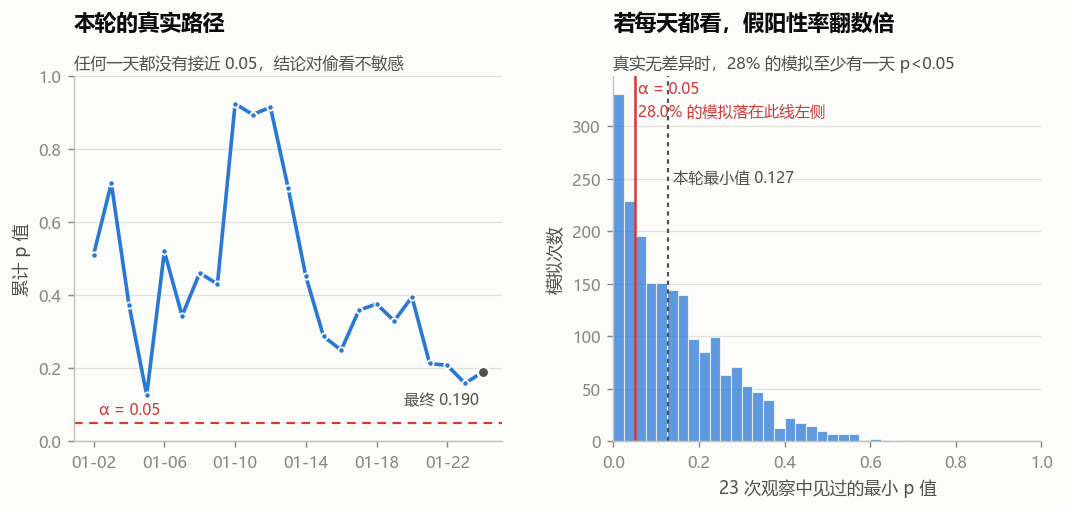

In [19]:
# 图 4：左 = 真实路径；右 = H0 下"看过的最小 p 值"分布
fig, axes = plt.subplots(1, 2, figsize=(9.6, 3.9), gridspec_kw={"wspace": 0.26})

ax = axes[0]
ax.plot(x, p_cum.to_numpy(), color=C_CTRL, lw=2, marker="o", ms=3.5,
        mec=SURFACE, mew=1.0)
ax.axhline(0.05, color=CRIT, lw=1.2, ls=(0, (4, 3)))
ax.text(0.3, 0.062, "α = 0.05", fontsize=8.5, color=CRIT, va="bottom")
ax.scatter([len(x) - 1], [p_cum.iloc[-1]], s=40, color=INK2, zorder=5,
           edgecolor=SURFACE, linewidth=1.4)
ax.annotate(f"最终 {p_cum.iloc[-1]:.3f}", xy=(len(x) - 1, p_cum.iloc[-1]),
            xytext=(len(x) - 1.2, 0.10), fontsize=8.5, color=INK2, ha="right")
ax.set_xticks(x[::4])
ax.set_xticklabels([f"{d:%m-%d}" for d in daily.index][::4])
ax.set_ylim(0, 1)
ax.set_ylabel("累计 p 值")
tidy(ax, title="本轮的真实路径", subtitle="任何一天都没有接近 0.05，结论对偷看不敏感")

ax = axes[1]
ax.hist(min_p, bins=40, range=(0, 1), color=C_CTRL, alpha=0.75,
        edgecolor=SURFACE, linewidth=0.6)
ymax = ax.get_ylim()[1]
ax.axvline(0.05, color=CRIT, lw=1.4)
ax.text(0.058, ymax * 0.99, f"α = 0.05\n{fpr_peek:.1%} 的模拟落在此线左侧",
        fontsize=8.5, color=CRIT, va="top", ha="left", linespacing=1.5)
ax.axvline(p_cum.min(), color=INK2, lw=1.2, ls=(0, (2, 2)))
ax.text(p_cum.min() + 0.012, ymax * 0.72, f"本轮最小值 {p_cum.min():.3f}",
        fontsize=8.5, color=INK2, va="center", ha="left")
ax.set_xlabel(f"{len(n_t_day)} 次观察中见过的最小 p 值")
ax.set_ylabel("模拟次数")
ax.set_xlim(0, 1)
tidy(ax, title="若每天都看，假阳性率翻数倍",
     subtitle=f"真实无差异时，{fpr_peek:.0%} 的模拟至少有一天 p<0.05")

plt.show()

在两组真实无差异的情况下，只做一次最终检验的假阳性率是 5.75%，每天都看会涨到 28.00%，接近 5 倍。这 28% 就是反复观察本身的代价。

本轮数据没有触发这个问题（最小累计 $p$ 值 0.127，离阈值很远），但流程上要有个说法：事先约定只看一次，或者改用任意时点有效的推断方法。

In [20]:
# ---- 8.3 任意时点有效的置信序列（mSPRT，高斯混合）----
# 在每个观察时点 t 构造混合似然比（对效应量取 N(0, τ²) 混合先验）：
#   Λ_t(θ0) = sqrt(V_t/(V_t+τ²)) * exp( τ²(d_t-θ0)² / (2 V_t (V_t+τ²)) )
# 由 Ville 不等式，{θ0 : max_t Λ_t(θ0) ≤ 1/α} 的覆盖概率 ≥ 1-α，
# 且不需要事先规定观察次数。该集合有闭式解：对每个 t 解出 |d_t - θ0| ≤ b_t，
# 取所有 t 的交集，得到 CI = [max_t (d_t - b_t), min_t (d_t + b_t)]。
TAU = 0.002   # 混合先验尺度：0.2 个百分点的绝对效应


def msprt_bounds(d_path, v_path, tau=TAU, alpha=0.05):
    # 每个时点的"可接受半径"，再沿时间取累积交集
    c = np.log(1 / (alpha * np.sqrt(v_path / (v_path + tau ** 2))))
    radius = np.sqrt(2 * c * v_path * (v_path + tau ** 2) / tau ** 2)
    return (np.maximum.accumulate(d_path - radius),
            np.minimum.accumulate(d_path + radius))


d_cum_arr, v_cum_arr = delta_cum.to_numpy(), se_cum.to_numpy() ** 2
av_low_path, av_high_path = msprt_bounds(d_cum_arr, v_cum_arr)
naive_low = (delta_cum - 1.96 * se_cum).to_numpy()
naive_high = (delta_cum + 1.96 * se_cum).to_numpy()

av_low, av_high = av_low_path[-1], av_high_path[-1]
print(f"最终时点 常规 95% CI      : [{naive_low[-1]*100:+.4f}%, {naive_high[-1]*100:+.4f}%]"
      f"  宽 {(naive_high[-1]-naive_low[-1])*100:.4f} pp")
print(f"最终时点 任意时点有效 CI  : [{av_low*100:+.4f}%, {av_high*100:+.4f}%]"
      f"  宽 {(av_high-av_low)*100:.4f} pp")
print(f"宽度代价                  : {(av_high-av_low)/(naive_high[-1]-naive_low[-1]):.2f}×")
print(f"是否包含 0                : {'是（仍不能拒绝原假设）' if av_low <= 0 <= av_high else '否'}")

最终时点 常规 95% CI      : [-0.3938%, +0.0781%]  宽 0.4719 pp
最终时点 任意时点有效 CI  : [-0.5335%, +0.2142%]  宽 0.7477 pp
宽度代价                  : 1.58×
是否包含 0                : 是（仍不能拒绝原假设）


In [21]:
# 验证：H0 下该置信序列的覆盖率（任意时点）
SIMS_COV = 500
covered_av, covered_naive = 0, 0
for _ in range(SIMS_COV):
    st = np.cumsum(rng.binomial(n_t_day, p_pool))
    sc = np.cumsum(rng.binomial(n_c_day, p_pool))
    dd = st / nT_cum - sc / nC_cum
    vv = (st / nT_cum) * (1 - st / nT_cum) / nT_cum + (sc / nC_cum) * (1 - sc / nC_cum) / nC_cum
    lo, hi = msprt_bounds(dd, vv)
    covered_av += bool(lo[-1] <= 0 <= hi[-1])
    pth = cumulative_p(st, nT_cum, sc, nC_cum)
    covered_naive += bool((pth >= 0.05).all())

print(f"H0 下，任意时点有效 CI 覆盖真值 0 的比例 : {covered_av/SIMS_COV:.3f}   （名义 0.95）")
print(f"H0 下，常规 CI 在「每天都看」时始终覆盖 0 : {covered_naive/SIMS_COV:.3f}")

H0 下，任意时点有效 CI 覆盖真值 0 的比例 : 0.994   （名义 0.95）
H0 下，常规 CI 在「每天都看」时始终覆盖 0 : 0.712


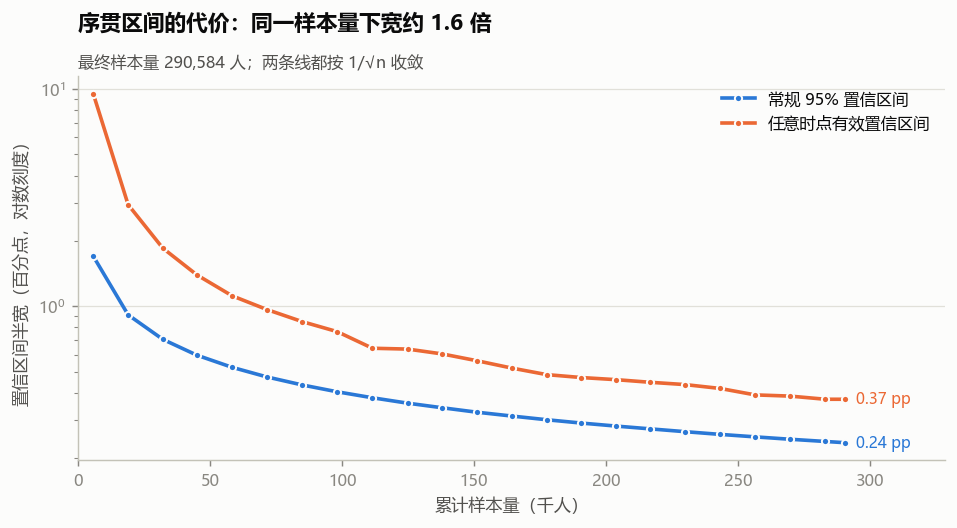

In [22]:
# 图 5：两种区间的半宽随样本量的收窄速度（同一个 y 轴，对数刻度）
fig, ax = plt.subplots(figsize=(8.6, 4.1))
cum_n = nT_cum + nC_cum
hw_naive = (naive_high - naive_low) / 2 * 100
hw_valid = (av_high_path - av_low_path) / 2 * 100

ax.plot(cum_n / 1000, hw_naive, color=C_CTRL, lw=2, marker="o", ms=4,
        mec=SURFACE, mew=1.1, label="常规 95% 置信区间")
ax.plot(cum_n / 1000, hw_valid, color=C_TREAT, lw=2, marker="o", ms=4,
        mec=SURFACE, mew=1.1, label="任意时点有效置信区间")

for series, color, name in [(hw_naive, C_CTRL, "常规"), (hw_valid, C_TREAT, "序贯")]:
    ax.annotate(f"{series[-1]:.2f} pp", xy=(cum_n[-1] / 1000, series[-1]),
                xytext=(6, 0), textcoords="offset points", fontsize=8.5,
                color=color, va="center")

ax.set_yscale("log")
ax.set_xlabel("累计样本量（千人）")
ax.set_ylabel("置信区间半宽（百分点，对数刻度）")
ax.set_xlim(0, cum_n[-1] / 1000 * 1.13)
tidy(ax, title="序贯区间的代价：同一样本量下宽约 1.6 倍",
     subtitle=f"最终样本量 {int(cum_n[-1]):,} 人；两条线都按 1/√n 收敛")
ax.legend(loc="upper right")
plt.show()

用任意时点有效的置信序列重新推断，最终区间是 $[-0.53\%,\ +0.21\%]$，比常规区间宽约 1.6 倍，依然跨 0。

两点：

- 如果当初用"每天看、随时可停"的合规流程，结论不会变。
- 如果用"每天看、看到显著就停"的做法，本轮没有误判（路径离阈值距离很远），但这个流程本身的假阳性率是 28%，这次没碰上不代表下次不会。

实际的解决方案二选一：实验前锁定分析时点，或者采用序贯推断并把区间变宽当作成本接受。

覆盖率 99.4% 高于名义的 95%，是因为 mSPRT 的边界来自 Ville 不等式的上界，对观察次数有限的情形偏保守。保守的代价就是区间更宽，这也是序贯方法的取舍。

## 9. 决策层：非劣效、等效与贝叶斯

$p>0.05$ 之后业务实际会问三类问题，对应三种统计工具，需要提前设定的东西也不一样。

| 业务问题 | 统计工具 | 需要提前设定 |
|---|---|---|
| 新页面更好吗？ | 双侧差异检验 + CI | $\alpha$ |
| 新页面不劣于旧页面吗（允许略差） | 非劣效检验（单侧） | 劣效界值 $\delta$ |
| 新旧页面等价吗？ | 等效性检验（TOST） | 等效界值 |

In [23]:
# ---- 9.1 非劣效检验：H0: Δ ≤ -δ  vs  H1: Δ > -δ ----
ni_rows = []
for margin in [0.001, 0.002, 0.003, 0.004, 0.005]:
    z_ni = (delta + margin) / se_delta
    p_ni = 1 - stats.norm.cdf(z_ni)
    ni_rows.append({
        "劣效界值 δ": margin,
        "所需单侧 p 值": p_ni,
        "结论": "可宣称非劣效" if p_ni < 0.05 else "不能宣称非劣效",
    })
ni = pd.DataFrame(ni_rows).set_index("劣效界值 δ")
display(ni.style.format({"劣效界值 δ": "{:.1f} pp", "所需单侧 p 值": "{:.4f}"}))

# 非劣效检验所需样本量（单侧 α=0.025）
nl_rows = []
for margin in [0.001, 0.002, 0.003]:
    need = ((stats.norm.ppf(0.975) + stats.norm.ppf(0.80)) ** 2
            * (p_c * (1 - p_c) + p_t * (1 - p_t)) / margin ** 2)
    nl_rows.append({"劣效界值 δ": margin, "每臂所需样本": need,
                    "当前每臂样本": n_c, "缺口倍数": need / n_c})
ni_power = pd.DataFrame(nl_rows).set_index("劣效界值 δ")
display(ni_power.style.format({"劣效界值 δ": "{:.1f} pp", "每臂所需样本": "{:,.0f}",
                               "当前每臂样本": "{:,.0f}", "缺口倍数": "{:.1f}×"}))

,所需单侧 p 值,结论
劣效界值 δ,,
0.001000,0.6845,不能宣称非劣效
0.002000,0.3630,不能宣称非劣效
0.003000,0.1188,不能宣称非劣效
0.004000,0.0221,可宣称非劣效
0.005000,0.0022,可宣称非劣效


,每臂所需样本,当前每臂样本,缺口倍数
劣效界值 δ,,,
0.001000,"1,652,865","145,274",11.4×
0.002000,"413,216","145,274",2.8×
0.003000,"183,652","145,274",1.3×


如果业务底线是"新页面最多比旧页面低 0.2 个百分点"，非劣效检验要求 $\Delta$ 的 95% 区间下界高于 $-0.2$ pp。实际下界 -0.394 pp，未通过。

结论对界值很敏感：界值放宽到 0.4 pp 才能宣称非劣效。而界值定多少不能由数据决定，必须在实验开始前写进方案；事后调整界值来宣称非劣效，等于 p-hacking。

要证明 0.2 pp 的非劣效，每臂需要约 41 万人，是当前样本量的近 3 倍。

In [24]:
# ---- 9.2 等效性检验（TOST 双侧）----
print("等效性检验：H0 为 |Δ| ≥ 界值，两个单侧检验都要通过")
for margin in [0.002, 0.003, 0.004]:
    p_1 = 1 - stats.norm.cdf((delta + margin) / se_delta)   # 检验 Δ > -margin
    p_2 = stats.norm.cdf((delta - margin) / se_delta)       # 检验 Δ < +margin
    p_tost = max(p_1, p_2)
    print(f"  界值 ±{margin*100:.1f} pp : TOST p = {p_tost:.4f} -> "
          f"{'可宣称等价' if p_tost < 0.05 else '不能宣称等价'}")
print("\n界值放宽到 ±0.4 pp 时才勉强通过，0.4 pp 相当于允许新页面相对下降 3.3%，")
print("这样的等价对业务没有意义。样本量不足以证明差异很小。")

等效性检验：H0 为 |Δ| ≥ 界值，两个单侧检验都要通过
  界值 ±0.2 pp : TOST p = 0.3630 -> 不能宣称等价
  界值 ±0.3 pp : TOST p = 0.1188 -> 不能宣称等价
  界值 ±0.4 pp : TOST p = 0.0221 -> 可宣称等价

界值放宽到 ±0.4 pp 时才勉强通过，0.4 pp 相当于允许新页面相对下降 3.3%，
这样的等价对业务没有意义。样本量不足以证明差异很小。


In [25]:
# ---- 9.3 贝叶斯决策：比较上线与不上线的期望损失 ----
M = 400_000
post_c = rng.beta(1 + k_c, 1 + n_c - k_c, M)
post_t = rng.beta(1 + k_t, 1 + n_t - k_t, M)

p_better = float(np.mean(post_t > post_c))
p_win_1pp = float(np.mean(post_t / post_c - 1 > 0.01))
loss_ship = float(np.mean(np.maximum(post_c - post_t, 0)))   # 上线错：本可保住却没保住
loss_hold = float(np.mean(np.maximum(post_t - post_c, 0)))   # 不上线错：本可提升却没拿到

print(f"P(新页面转化率 > 旧页面)     : {p_better:.4f}")
print(f"P(新页面相对提升 > 1%)       : {p_win_1pp:.4f}")
print(f"上线后的期望损失 E[max(p_c-p_t,0)] : {loss_ship*100:.4f} pp")
print(f"不上线的期望损失 E[max(p_t-p_c,0)] : {loss_hold*100:.4f} pp")
print(f"期望损失比                        : {loss_ship/loss_hold:.0f} : 1 -> 保持旧页面")

P(新页面转化率 > 旧页面)     : 0.0951
P(新页面相对提升 > 1%)       : 0.0106
上线后的期望损失 E[max(p_c-p_t,0)] : 0.1630 pp
不上线的期望损失 E[max(p_t-p_c,0)] : 0.0053 pp
期望损失比                        : 31 : 1 -> 保持旧页面


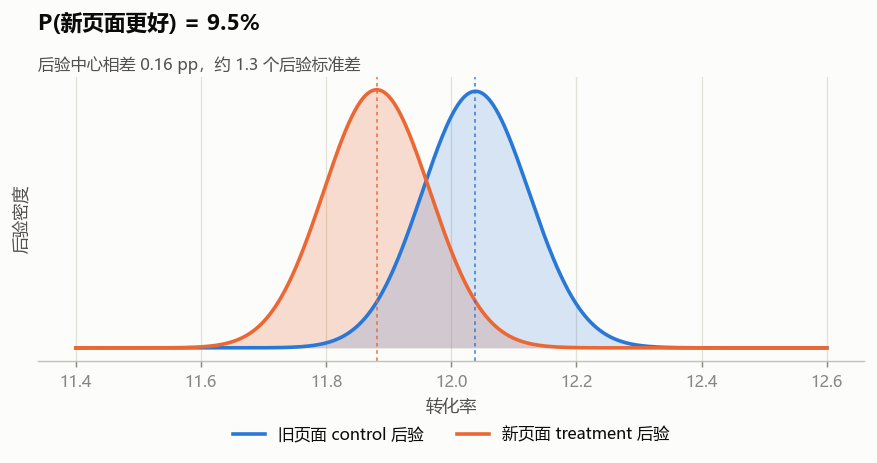

In [26]:
# 图 6：两组后验分布（Beta 后验，均匀先验）
grid_p = np.linspace(0.114, 0.126, 800)
dens_c = stats.beta.pdf(grid_p, 1 + k_c, 1 + n_c - k_c)
dens_t = stats.beta.pdf(grid_p, 1 + k_t, 1 + n_t - k_t)

fig, ax = plt.subplots(figsize=(8.2, 3.9))
ax.fill_between(grid_p * 100, dens_t, color=C_TREAT, alpha=0.22, lw=0)
ax.fill_between(grid_p * 100, dens_c, color=C_CTRL, alpha=0.18, lw=0)
ax.plot(grid_p * 100, dens_c, color=C_CTRL, lw=2, label="旧页面 control 后验")
ax.plot(grid_p * 100, dens_t, color=C_TREAT, lw=2, label="新页面 treatment 后验")

for val, color in [(p_c, C_CTRL), (p_t, C_TREAT)]:
    ax.axvline(val * 100, color=color, lw=1, ls=(0, (2, 2)), alpha=0.8)

var_c = (1 + k_c) * (1 + n_c - k_c) / ((2 + n_c) ** 2 * (3 + n_c))
var_t = (1 + k_t) * (1 + n_t - k_t) / ((2 + n_t) ** 2 * (3 + n_t))
z_post = (p_c - p_t) / np.sqrt(var_c + var_t)

ax.set_xlabel("转化率")
ax.set_ylabel("后验密度")
ax.set_yticks([])
ax.spines["left"].set_visible(False)
tidy(ax, grid_axis="x", title=f"P(新页面更好) = {p_better:.1%}",
     subtitle=f"后验中心相差 {abs(p_c-p_t)*100:.2f} pp，约 {z_post:.1f} 个后验标准差")
ax.legend(loc="upper center", ncols=2, bbox_to_anchor=(0.5, -0.18))
ax.figure.subplots_adjust(bottom=0.27)
plt.show()

In [27]:
# ---- 9.4 决策矩阵 ----
decision = pd.DataFrame({
    "业务问题": ["新页面更好吗？", "新页面不劣于旧页面吗？", "新旧页面等价吗？",
                "实验能回答这个问题吗？", "现在上线划算吗？"],
    "统计工具": ["双侧差异检验 + CI", "非劣效检验（δ=0.2pp）", "等效性检验（±0.3pp）",
                 "MDE / 功效分析", "贝叶斯期望损失"],
    "本轮结论": [
        f"否。p={p_value:.3f}，CI [{ci_low*100:+.3f}%, {ci_high*100:+.3f}%]",
        "否。CI 下界 -0.394pp < -0.2pp",
        "否。TOST p>0.05",
        f"否。仅能检出 ≥{mde_rel:.2%} 相对提升",
        f"否。期望损失 {loss_ship*100:.3f}pp vs {loss_hold*100:.3f}pp",
    ],
}).set_index("业务问题")
display(decision.style.set_properties(**{"text-align": "left"}))

,统计工具,本轮结论
业务问题,,
新页面更好吗？,双侧差异检验 + CI,"否。p=0.190，CI [-0.394%, +0.078%]"
新页面不劣于旧页面吗？,非劣效检验（δ=0.2pp）,否。CI 下界 -0.394pp < -0.2pp
新旧页面等价吗？,等效性检验（±0.3pp）,否。TOST p>0.05
实验能回答这个问题吗？,MDE / 功效分析,否。仅能检出 ≥2.80% 相对提升
现在上线划算吗？,贝叶斯期望损失,否。期望损失 0.163pp vs 0.005pp


五个问题的答案都是否定的，频率派的检验和贝叶斯后验指向同一个动作：保持旧页面。

最后一行比前几行更要紧。本轮实验没有能力回答"1% 的提升是否存在"，所以"不上线"的理由不该是"实验证明新页面无效"，而是"这轮实验支撑不了上线决策，需要重新设计"。

## 10. 敏感性分析

前面的清洗规则和分析口径都带判断。换一个合理的口径，结论会不会翻转？

下表放了 8 种口径：主口径、4 种清洗变体、2 种时间切分，以及按天分块的估计。

In [28]:
def estimate(df, label, assign_by="group"):
    # 按给定口径估计转化率差及其 95% CI
    key = "group" if assign_by == "group" else "landing_page"
    control_key = "control" if assign_by == "group" else "old_page"
    treat_key = "treatment" if assign_by == "group" else "new_page"

    a = df[df[key] == control_key]["converted"]
    b = df[df[key] == treat_key]["converted"]
    n_a, n_b = len(a), len(b)
    p_a, p_b = a.mean(), b.mean()
    d = p_b - p_a
    se = np.sqrt(p_b * (1 - p_b) / n_b + p_a * (1 - p_a) / n_a)
    pv = 2 * stats.norm.sf(abs(d / se))
    return {"口径": label, "样本量": n_a + n_b, "效应_pp": d * 100,
            "CI下限": (d - 1.96 * se) * 100, "CI上限": (d + 1.96 * se) * 100,
            "p值": pv}


first_record = raw.sort_values("ts").drop_duplicates(subset="user_id", keep="first")
full_window = clean[(clean["ts"] >= "2017-01-03") & (clean["ts"] < "2017-01-24")]

sensitivity = pd.DataFrame([
    estimate(clean, "主口径：有效曝光 + 首次记录"),
    estimate(first_record, "ITT：保留全部首次记录（不剔除错配）"),
    estimate(first_record, "As-treated：按实际曝光页面", assign_by="landing_page"),
    estimate(clean[~clean["user_id"].isin(cross_group.index)], "剔除跨组重复上报用户"),
    estimate(full_window, "剔除首尾半天（01-03 ~ 01-23）"),
    estimate(clean[clean["day"] <= pd.Timestamp("2017-01-08").date()], "仅前 7 天"),
    estimate(clean[clean["day"] >= pd.Timestamp("2017-01-18").date()], "仅后 7 天"),
]).set_index("口径")

sensitivity.loc["按天分块（事后分层）"] = {
    "样本量": len(clean), "效应_pp": strat_delta * 100,
    "CI下限": (strat_delta - 1.96 * strat_se) * 100,
    "CI上限": (strat_delta + 1.96 * strat_se) * 100,
    "p值": 2 * stats.norm.sf(abs(strat_delta / strat_se)),
}

display(sensitivity.style.format({
    "样本量": "{:,.0f}", "效应_pp": "{:+.4f}", "CI下限": "{:+.4f}",
    "CI上限": "{:+.4f}", "p值": "{:.4f}",
}))

all_negative = bool((sensitivity["效应_pp"] < 0).all())
all_ns = bool((sensitivity["p值"] > 0.05).all())
all_span_zero = bool(((sensitivity["CI下限"] < 0) & (sensitivity["CI上限"] > 0)).all())
print(f"所有口径方向一致（均为负）: {all_negative}")
print(f"所有口径均不显著          : {all_ns}")
print(f"所有口径的 CI 均跨越 0    : {all_span_zero}")
print(f"效应量范围                : {sensitivity['效应_pp'].min():+.4f} ~ "
      f"{sensitivity['效应_pp'].max():+.4f} pp")

,样本量,效应_pp,CI下限,CI上限,p值
口径,,,,,
主口径：有效曝光 + 首次记录,"290,584",-0.1578,-0.3938,+0.0781,0.1899
ITT：保留全部首次记录（不剔除错配）,"290,584",-0.1587,-0.3947,+0.0773,0.1876
As-treated：按实际曝光页面,"290,584",-0.1781,-0.4141,+0.0579,0.1391
剔除跨组重复上报用户,"288,689",-0.1473,-0.3840,+0.0894,0.2226
剔除首尾半天（01-03 ~ 01-23）,"277,437",-0.1635,-0.4049,+0.0780,0.1845
仅前 7 天,"84,924",-0.1633,-0.5983,+0.2717,0.4619
仅后 7 天,"86,786",-0.2193,-0.6523,+0.2138,0.3210
按天分块（事后分层）,"290,584",-0.1579,-0.3938,+0.0781,0.1897


所有口径方向一致（均为负）: True
所有口径均不显著          : True
所有口径的 CI 均跨越 0    : True
效应量范围                : -0.2193 ~ -0.1473 pp


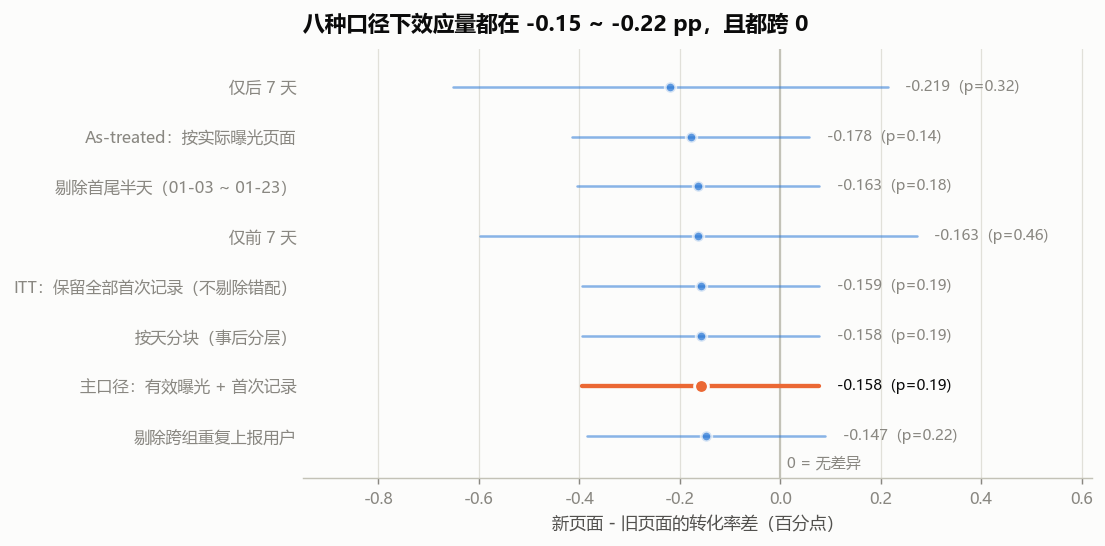

In [29]:
# 图 7：森林图 —— 口径变了，结论不变
order = sensitivity.sort_values("效应_pp").index[::-1]
fig, ax = plt.subplots(figsize=(8.6, 4.3))
y = np.arange(len(order))

for i, name in enumerate(order):
    row = sensitivity.loc[name]
    is_main = name.startswith("主口径")
    color = C_TREAT if is_main else C_CTRL
    lw = 2.4 if is_main else 1.4
    ax.plot([row["CI下限"], row["CI上限"]], [i, i], color=color, lw=lw,
            solid_capstyle="round", alpha=1.0 if is_main else 0.55, zorder=2)
    ax.scatter([row["效应_pp"]], [i], s=58 if is_main else 34, color=color,
               zorder=3, edgecolor=SURFACE, linewidth=1.6,
               alpha=1.0 if is_main else 0.75)
    ax.text(row["CI上限"] + 0.035, i, f"{row['效应_pp']:+.3f}  (p={row['p值']:.2f})",
            va="center", fontsize=8.3,
            color=INK if is_main else MUTED)

ax.axvline(0, color=BASE, lw=1.2, zorder=1)
ax.text(0.014, -0.55, "0 = 无差异", fontsize=8.3, color=MUTED, va="center")
ax.set_ylim(-0.85, len(order) - 0.25)
ax.set_yticks(y)
ax.set_yticklabels(order, fontsize=9)
ax.set_xlabel("新页面 - 旧页面的转化率差（百分点）")
ax.set_xlim(-0.95, 0.62)
ax.grid(False)
ax.grid(axis="x", color=GRID, lw=0.7)
ax.set_axisbelow(True)
for side in ("top", "right", "left"):
    ax.spines[side].set_visible(False)
ax.spines["bottom"].set_color(BASE)
ax.tick_params(axis="y", length=0)
ax.set_title("八种口径下效应量都在 -0.15 ~ -0.22 pp，且都跨 0", loc="left", pad=10)
plt.tight_layout()
plt.show()

八种口径的效应量落在 -0.147 到 -0.219 pp 之间，方向一致，全部不显著、全部跨 0。清洗规则怎么选都不改变结论。

两点补充：

- As-treated 口径的效应更负（-0.178 pp）。这个口径不看分组标签，只按用户实际看到的页面归组，负效应反而略大，说明主口径的清洗没有掩盖不利信号，只是把负向效应的量级缩小了一点。
- 仅后 7 天的效应更负（-0.219 pp），但样本只有全期的 30%，区间更宽，不足以说"效果在恶化"。第 7 节的斜率检验 $p=0.987$，可以排除时间趋势。

## 11. 结论与建议

### 11.1 决策建议

不上线新页面。这里需要说清楚的是：

> 在 23 个自然日、29 万用户的实验中，新页面转化率 11.88%，低于旧页面的 12.04%，绝对差 -0.158 个百分点（相对 -1.31%，95% CI $[-0.394\%, +0.078\%]$）。差异不显著，而本轮样本量只能检出 ≥2.80% 的相对提升，因此既不能证明新页面有提升，也不能证明它没差别，1% 量级的改版问题这轮实验回答不了。

### 11.2 行动项

| 优先级 | 行动 | 依据 |
|---|---|---|
| P0 | 修复分组标签与页面下发的一致性，实验开始前跑 SRM 和"分组-曝光明细"一致性校验 | 第 3 节：1,895 人跨组重复上报、1,998 人组内串流，合计 3,893 条错配记录 |
| P0 | 下一轮实验先算样本量再开跑，把 MDE 写进实验方案 | 第 6 节：MDE 2.80%，与业务关心的 1% 差一个数量级 |
| P1 | 换更灵敏的观测指标（加购率、CTA 点击率），或把多个改动打包成一次实验 | 第 6 节：12% 的基线转化率使所需样本量极大，1% 提升需 115 万/臂 |
| P1 | 沉淀实验前行为数据，为后续 CUPED 做准备 | 第 7 节：分块无收益，降方差只能靠用户级协变量 |
| P2 | 固化实验流程：锁定分析时点，或采用序贯推断 | 第 8 节：每天偷看把假阳性率从 5% 抬到 28% |
| P2 | 若目标是"不劣于"，在实验方案中预先登记劣效界值 | 第 9 节：事后调整界值等于 p-hacking |

### 11.3 分析边界

- 数据只有 `user_id / timestamp / group / landing_page / converted`，没有订单金额、利润或商品信息，结论只讨论转化率，不涉及收入。
- 没有设备、渠道、地域等用户属性，无法做异质性分析或 uplift 建模，也评估不了"新页面对某类用户更好"这类假设。
- 没有实验前行为数据，无法做 CUPED 一类方差缩减，这是本轮只能靠加样本量的根本原因。
- 只有一个指标，没有护栏指标（跳出率、加载时长、客服投诉等）。真实上线决策需要护栏指标配合。
- 非劣效和等效的结论强烈依赖界值选择，界值应来自业务成本核算，不能由数据反推。
- 没有处理多重比较：若同时检验多个指标或多个分群，$\alpha$ 需要相应调整。

## 12. Tableau 看板

给业务方看的版本，可以按分组筛选。

<iframe
    src="https://public.tableau.com/views/ABtest_17871506401860/1?:showVizHome=no"
    width="100%"
    height="820"
    frameborder="0"
    title="电商落地页 A/B Test 决策看板">
</iframe>

GitHub 会过滤 Notebook 里的 `iframe`，看不到的话直接打开 [Tableau Public 看板](https://public.tableau.com/views/ABtest_17871506401860/1?:showVizHome=no)。

Tableau 那版给业务看结论，这个 Notebook 记录推断过程和稳健性检查，两边面向的读者不同。

## 附录：复现说明

| 项目 | 说明 |
|---|---|
| 数据 | `data/raw/ab_data.csv`（294,478 行），来源与校验值见 `DATA_SOURCES.md` |
| 随机种子 | `RNG_SEED = 20260101`，所有模拟（置换、bootstrap、A/A、偷看、覆盖率）均固定种子 |
| 产出 | `data/processed/ab_clean.csv`（清洗后分析样本）、`data/processed/tableau_summary.csv`（看板数据源） |
| 运行 | 见 README 的"本地运行"一节；从上到下顺序执行即可 |

模拟参数一览：

| 模块 | 模拟次数 | 用途 |
|---|---:|---|
| 置换检验 | 50,000 | 无分布假设的 p 值 |
| bootstrap | 20,000 | 效应量经验置信区间 |
| A/A 校准 | 5,000 | 验证假阳性率与 CI 覆盖率 |
| 偷看膨胀 | 2,000 | H0 下"看过的最小 p 值"分布 |
| 置信序列覆盖率 | 500 | 验证任意时点有效区间 |
| 贝叶斯后验 | 400,000 抽样 | 后验概率与期望损失 |

这些模拟只用来检查方法本身是否可靠，不参与结论。所有结论数字都来自真实的 290,584 位用户数据，没有使用任何合成数据。